# UK Savoury Snacks – Exploratory Data Analysis (EDA)

**Goal of EDA:** understand the data *before* analysing it – what each tab contains, whether it is clean, how the fields relate,
and what first patterns suggest. Every step ends with **"What we learn"** and, where needed, a **decision** that feeds the analysis.

**EDA plan**
1. Load all tabs and check structure
2. Data quality (missing, duplicates, zeros, outliers)
3. Time coverage & seasonality → choose comparison period
4. Hierarchy / mapping checks
5. Market structure (who and what sells)
6. Growth: this year vs last year
7. Channel mix: online vs in-store
8. Price per unit
9. PepsiCo portfolio
10. Shopper tabs: demographics, basket bands, CSN, cross-buying
11. EDA summary: observations, data decisions, hypotheses

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
NAVY, ORANGE, GREY = '#1B2A4A', '#E8833A', '#9AA5B1'

SOURCE = 'Case_Study_Commercial_Insights.xlsx'   # converted source file (same folder)

## Step 1 – Load every tab and check its shape
The sales tab is called **'Name mapping'** in the source file even though it holds the weekly sales data.

In [2]:
tabs = pd.read_excel(SOURCE, sheet_name=None)   # ~1-2 min: 1m rows
for name, df in tabs.items():
    print(f'{name:28s} rows={df.shape[0]:>9,}  cols={df.shape[1]}')
sales = tabs['Name mapping']
dem, bb, csn, cb = tabs['Demographic Data'], tabs['Basket_bands'], tabs['CSN_metrics'], tabs['Basket_Combination_Data']

Basket_Combination_Data      rows=       11  cols=7
Demographic Data             rows=       27  cols=4
Basket_bands                 rows=       39  cols=5
CSN_metrics                  rows=        2  cols=6
Name mapping                 rows=1,011,594  cols=17


**What we learn:** one big fact table (sales, ~1m rows) and four small shopper tables. The analysis will mostly run on sales; the small tabs add the shopper view.

## Step 2 – Structure of the sales table: columns, types, sample rows, cardinality

In [3]:
print(sales.dtypes); sales.head(3)

Customer Name          str
STORE FORMAT           str
SUPPLIER               str
Category               str
Segment                str
Sub segment            str
Brand Name             str
Sub Brand Name         str
Product Name           str
Flavour                str
Pack format            str
Sub pack format        str
Number of packs    float64
YEAR                 int64
WEEK                 int64
VALUE SALES        float64
UNIT SALES         float64
dtype: object


,Customer Name,STORE FORMAT,SUPPLIER,Category,Segment,Sub segment,Brand Name,Sub Brand Name,Product Name,Flavour,Pack format,Sub pack format,Number of packs,YEAR,WEEK,VALUE SALES,UNIT SALES
0,Asdaria Supermarkets,LARGE FORMAT,Heritage Pantry Foods,SAVOURY SNACKS,SALTY SNACKS,EXTRUDED SNACKS,AmberVale,Bold Crunch,Salt & Vinegar Vibes Crunch,SALT & VINEGAR VIBES,SINGLE,STANDARDS,5.00,2024,37,488.01,278.26
1,Asdaria Supermarkets,LARGE FORMAT,Heritage Pantry Foods,SAVOURY SNACKS,SALTY SNACKS,EXTRUDED SNACKS,AmberVale,Bold Crunch,Salt & Vinegar Vibes Crunch,SALT & VINEGAR VIBES,SINGLE,STANDARDS,5.00,2024,38,479.16,273.91
2,Asdaria Supermarkets,LARGE FORMAT,Heritage Pantry Foods,SAVOURY SNACKS,SALTY SNACKS,EXTRUDED SNACKS,AmberVale,Bold Crunch,Salt & Vinegar Vibes Crunch,SALT & VINEGAR VIBES,SINGLE,STANDARDS,5.00,2024,39,502.41,292.09


In [4]:
card = sales.nunique().sort_values()
card.to_frame('unique values')

,unique values
Category,1
YEAR,2
STORE FORMAT,5
Customer Name,5
Pack format,5
Segment,7
Sub pack format,8
Sub segment,22
Number of packs,27
WEEK,52


**What we learn**
- Text columns describe *who / what / where* (Customer, Store format, Supplier, Brand, Segment, Sub segment, Pack…); numeric columns are *when* (YEAR, WEEK) and *how much* (VALUE SALES, UNIT SALES).
- One row = one product at one retailer & store format in one week.
- Category has 1 value (all Savoury Snacks), 5 customers, 5 store formats, 22 sub-segments, 227 suppliers, ~550 brands, ~2,500 products.

## Step 3 – Data quality
### 3a. Missing values

In [5]:
miss = sales.isna().sum(); miss[miss > 0].to_frame('missing rows')

,missing rows
Flavour,7385
Number of packs,3186


Only **Flavour** and **Number of packs** have gaps – neither is needed for £ analysis. → *Decision: keep rows.*

### 3b. Duplicates

In [6]:
dups = sales[sales.duplicated()]
print(f'Exact duplicate rows: {len(dups):,}  |  £ in duplicates: £{dups["VALUE SALES"].sum():,.0f}  '
      f'({dups["VALUE SALES"].sum() / sales["VALUE SALES"].sum():.6%} of total)')

Exact duplicate rows: 1,600  |  £ in duplicates: £700  (0.000031% of total)


Duplicates are almost all zero-sales rows → negligible. → *Decision: keep (no SKU code to prove they are true duplicates; impact ≈ £0).*

### 3c. Zero and negative values

In [7]:
print('Negative value rows:', (sales['VALUE SALES'] < 0).sum())
print('Zero value rows    :', (sales['VALUE SALES'] == 0).sum(), f"({(sales['VALUE SALES'] == 0).mean():.0%} of rows)")

Negative value rows: 0
Zero value rows    : 174469 (17% of rows)


~17% of rows are products listed but not selling that week. They don't change totals, but would distort averages. → *Decision: exclude zero rows when calculating price per unit.*

### 3d. Odd values

In [8]:
print('Store formats:\n', sales.groupby('STORE FORMAT')['VALUE SALES'].sum().map('£{:,.0f}'.format))
print('\nRows with Number of packs = 0:', (sales['Number of packs'] == 0).sum())
s = sales[sales['UNIT SALES'] > 0]
ppu = s['VALUE SALES'] / s['UNIT SALES']
print('\nPrice per unit percentiles:'); print(ppu.quantile([0, .01, .5, .99, 1]).round(2))
print('Units with decimals (share of rows):', f"{(sales['UNIT SALES'] % 1 != 0).mean():.0%}")

Store formats:
 STORE FORMAT
E-COMMERCE        £319,586,534
LARGE FORMAT    £1,580,529,287
PURE PLAY          £59,989,721
SMALL FORMAT      £318,349,711
UNALLOCATED             £5,553
Name: VALUE SALES, dtype: str

Rows with Number of packs = 0: 734



Price per unit percentiles:
0.00    0.01
0.01    0.50
0.50    1.66
0.99    4.86
1.00   99.00
dtype: float64


Units with decimals (share of rows): 83%


**What we learn**
- **UNALLOCATED** store format is only ~£5.5k across two years (0.0002%) → *exclude.*
- A few rows have *Number of packs = 0* (impossible) and a handful of £/unit outliers (> £20) → tiny; ignore or cap when doing price work.
- Units have decimals → confirms the data is **sanitised** (brief says so). Read relative patterns, not exact £.

## Step 4 – Time coverage & seasonality (the most important EDA decision)

      min  max  nunique
YEAR                   
2024    1   52       52
2025    1   47       47


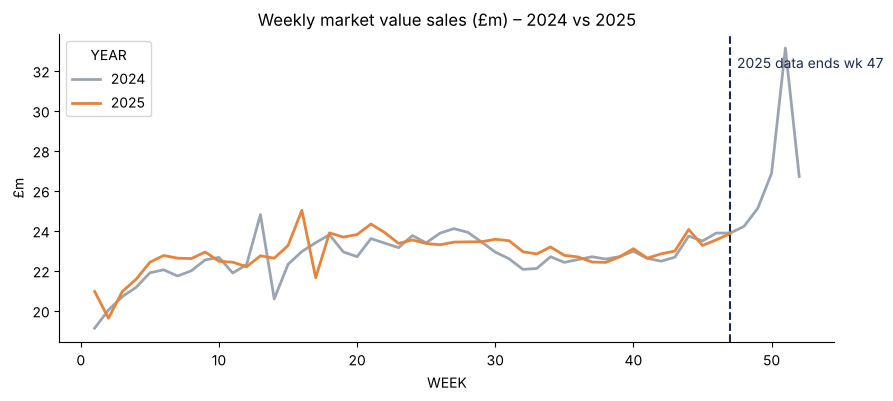

In [9]:
print(sales.groupby('YEAR')['WEEK'].agg(['min', 'max', 'nunique']))
wk = sales.pivot_table(index='WEEK', columns='YEAR', values='VALUE SALES', aggfunc='sum') / 1e6
ax = wk.plot(color=[GREY, ORANGE], lw=2, title='Weekly market value sales (£m) – 2024 vs 2025')
ax.axvline(47, ls='--', color=NAVY); ax.text(47.5, wk.max().max() * 0.97, '2025 data ends wk 47', color=NAVY)
ax.set_ylabel('£m'); plt.show()

In [10]:
full_2024 = sales.loc[sales.YEAR == 2024, 'VALUE SALES'].sum()
ytd_2025 = sales.loc[sales.YEAR == 2025, 'VALUE SALES'].sum()
lfl_2024 = sales.loc[(sales.YEAR == 2024) & (sales.WEEK <= 47), 'VALUE SALES'].sum()
print(f'Naive: 2025 (47 wks) vs 2024 (52 wks): {ytd_2025 / full_2024 - 1:+.1%}   <- misleading')
print(f'Like-for-like wk1-47 vs wk1-47     : {ytd_2025 / lfl_2024 - 1:+.1%}   <- correct')

Naive: 2025 (47 wks) vs 2024 (52 wks): -10.3%   <- misleading
Like-for-like wk1-47 vs wk1-47     : +1.2%   <- correct


**What we learn:** 2025 stops at week 47, and weeks 48–52 are the **Christmas peak** (week 51 ≈ £33m vs ~£23m normal).
Comparing the two years naively would show a fake ~-10% decline.
Also visible: the **Easter spike moves** (week 13 in 2024, week 16 in 2025), so single weeks are noisy – compare period totals, not individual weeks.
→ **Decision: compare 2025 wk1–47 (TY) with 2024 wk1–47 (YA).**

In [11]:
d = sales[(sales.WEEK <= 47) & (sales['STORE FORMAT'] != 'UNALLOCATED')].copy()
d['Period'] = d.YEAR.map({2024: 'YA', 2025: 'TY'})
d['Channel'] = np.where(d['STORE FORMAT'].isin(['E-COMMERCE', 'PURE PLAY']), 'Online', 'In-store')
d['PepsiCo'] = d.SUPPLIER.eq('PepsiCo')
ty, ya = d[d.Period == 'TY'], d[d.Period == 'YA']
print(f'Working data: {len(d):,} rows | TY £{ty["VALUE SALES"].sum()/1e6:,.1f}m | YA £{ya["VALUE SALES"].sum()/1e6:,.1f}m')

Working data: 959,268 rows | TY £1,077.4m | YA £1,065.0m


## Step 5 – Hierarchy & mapping checks
Do the fields nest cleanly? If not, we choose the cleanest level to analyse.

In [12]:
seg_sub = d.groupby('Sub segment')['Segment'].unique()
print('Sub-segments sitting in more than one segment:'); print(seg_sub[seg_sub.apply(len) > 1])
print('\nSegment list:', sorted(d.Segment.unique()))

Sub-segments sitting in more than one segment:
Sub segment
SNACK MIX    [SALTY SNACKS, PRIVATE LABEL]
Name: Segment, dtype: object

Segment list: ['CRISPS', 'DIPS', 'NUT SNACKS', 'OTHER SALTY SNACKS', 'PRIVATE LABEL', 'SALTY SNACKS', 'SAVOURY SNACKS']


In [13]:
pd.crosstab(d['Customer Name'], d['STORE FORMAT'])

STORE FORMAT,E-COMMERCE,LARGE FORMAT,PURE PLAY,SMALL FORMAT
Customer Name,,,,
Acadia Grocers,0,0,132663,0
Asdaria Supermarkets,77520,95218,0,13857
Escora Retail,59738,69679,0,55345
Morees Markets,87857,128783,0,0
Saintbury Stores,83778,100956,0,53874


In [14]:
pd.crosstab(d['Pack format'], d['Sub pack format'])

Sub pack format,GRABS,LARGE MULTIPACK,MEDIUM MULTIPACK,NUTS,SALSA DIPS,SHARING,SMALL MULTIPACK,STANDARDS
Pack format,,,,,,,,
MULTIPACK,0,14049,23266,0,0,0,179758,0
NUTS,0,0,0,150883,0,0,0,0
SALSA DIPS,0,0,0,0,10509,0,0,0
SHARING,0,0,0,0,0,454237,94,0
SINGLE,42509,0,0,0,0,0,94,83869


In [15]:
bs = d.groupby('Brand Name')['SUPPLIER'].nunique()
print('Brand names used by >1 supplier:', (bs > 1).sum())
print('...of which PepsiCo brands:', d[d['Brand Name'].isin(bs[bs > 1].index) & d.PepsiCo]['Brand Name'].nunique())

Brand names used by >1 supplier: 52
...of which PepsiCo brands: 0


**What we learn**
- **Segment is messy:** 'PRIVATE LABEL' is a segment (it's really *who makes it*), and SNACK MIX sits in two segments. → *Decision: analyse at **Sub segment** level.*
- **Acadia Grocers only sells via PURE PLAY** = online-only retailer. Morees has no small format.
- Pack format ↔ Sub pack format nests almost perfectly (a few hundred stray rows). → *Use Sub pack format for detail.*
- Some brand names are reused by different suppliers (sanitised names) but none of PepsiCo's → *analyse brands as Brand + Supplier.*
- **Channel is not a column** → *derived: E-COMMERCE + PURE PLAY = Online; LARGE + SMALL = In-store.*

## Step 6 – Market structure: who and what sells (TY)

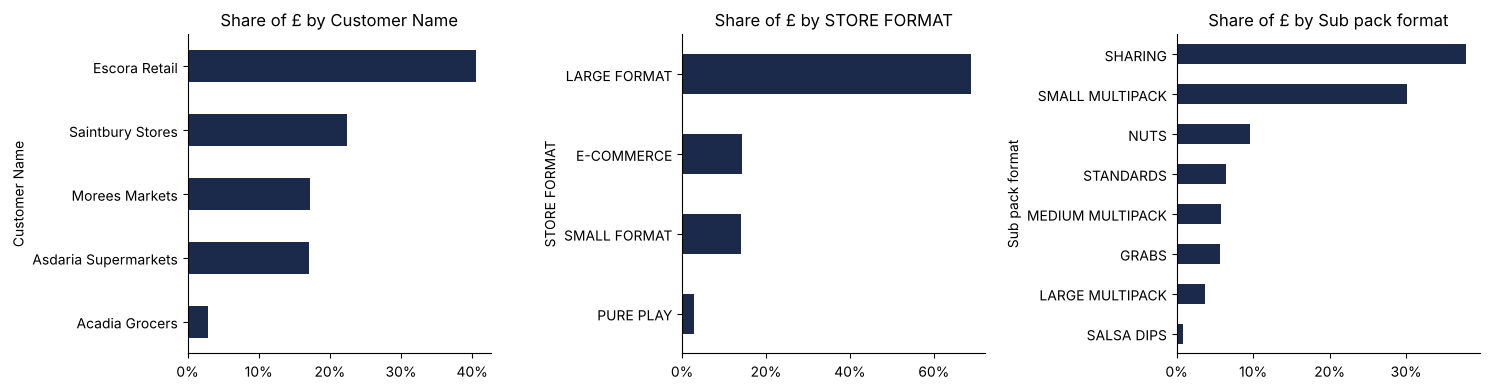

In [16]:
def mix(col, df=ty, n=10):
    s = df.groupby(col)['VALUE SALES'].sum().sort_values(ascending=False)
    return (s / s.sum()).head(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Customer Name', 'STORE FORMAT', 'Sub pack format']):
    mix(col).sort_values().plot.barh(ax=ax, color=NAVY, title=f'Share of £ by {col}')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
plt.tight_layout(); plt.show()

PepsiCo share: 36.9% | Top-5 suppliers: 73.3% | Top-10: 88.4%


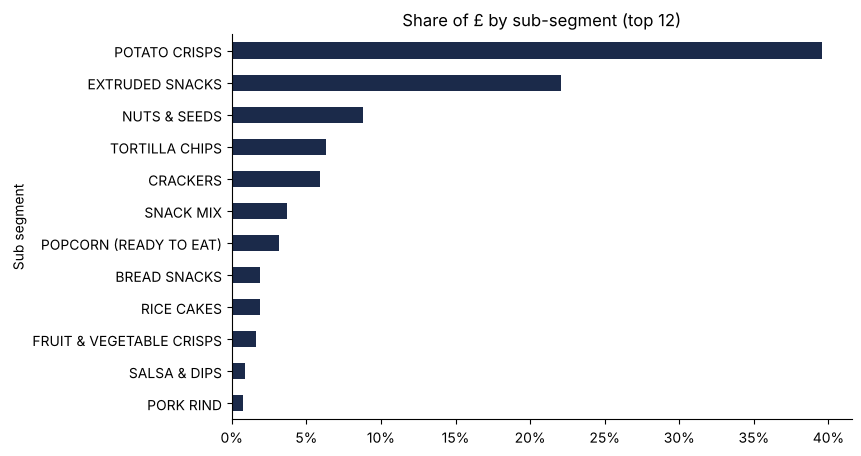

In [17]:
sup = mix('SUPPLIER', n=30)
print(f'PepsiCo share: {sup["PepsiCo"]:.1%} | Top-5 suppliers: {sup.head(5).sum():.1%} | Top-10: {sup.head(10).sum():.1%}')
ax = mix('Sub segment', n=12).sort_values().plot.barh(color=NAVY, title='Share of £ by sub-segment (top 12)', figsize=(8, 5))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}')); plt.show()

**What we learn**
- Escora Retail ≈ 41% of sales; Acadia is small (~3%) – but small isn't the same as unimportant (see growth).
- Large format stores ≈ 69%; online (E-commerce + Pure play) ≈ 17%.
- PepsiCo is the clear leader (~37%); market is concentrated in a few suppliers.
- Potato Crisps (~40%) and Extruded (~22%) dominate; Sharing and Small multipack are the main packs.

## Step 7 – Growth: TY vs YA (market and PepsiCo)

In [18]:
def growth(col, df=d):
    g = df.pivot_table(index=col, columns='Period', values='VALUE SALES', aggfunc='sum', fill_value=0)
    p = df[df.PepsiCo].pivot_table(index=col, columns='Period', values='VALUE SALES', aggfunc='sum', fill_value=0).reindex(g.index).fillna(0)
    out = pd.DataFrame({'TY £m': g.TY / 1e6, 'growth %': (g.TY / g.YA - 1) * 100,
                        '£m change': (g.TY - g.YA) / 1e6,
                        'contribution %': (g.TY - g.YA) / (g.TY.sum() - g.YA.sum()) * 100,
                        'PepsiCo share %': p.TY / g.TY * 100,
                        'share chg pts': (p.TY / g.TY - p.YA / g.YA) * 100})
    return out.sort_values('TY £m', ascending=False).round(1)
growth('Channel')

,TY £m,growth %,£m change,contribution %,PepsiCo share %,share chg pts
Channel,,,,,,
In-store,893.80,0.30,2.30,18.50,37.00,-0.80
Online,183.60,5.80,10.10,81.50,36.30,-0.90


In [19]:
growth('Customer Name')

,TY £m,growth %,£m change,contribution %,PepsiCo share %,share chg pts
Customer Name,,,,,,
Escora Retail,437.40,2.00,8.40,68.20,41.80,0.50
Saintbury Stores,241.30,1.20,2.90,23.40,35.00,-0.70
Morees Markets,185.00,-1.20,-2.30,-18.90,27.00,-1.50
Asdaria Supermarkets,183.50,-0.40,-0.70,-5.60,39.90,-3.50
Acadia Grocers,30.20,15.50,4.10,32.90,24.80,-2.60


In [20]:
sg = growth('Sub segment')
sg.head(12)

,TY £m,growth %,£m change,contribution %,PepsiCo share %,share chg pts
Sub segment,,,,,,
POTATO CRISPS,426.40,-2.90,-12.90,-104.70,46.40,-0.20
EXTRUDED SNACKS,238.10,-0.40,-0.90,-7.50,49.30,-0.70
NUTS & SEEDS,94.70,4.00,3.60,29.50,7.20,1.70
TORTILLA CHIPS,68.20,2.20,1.50,12.00,80.90,0.10
CRACKERS,64.10,17.40,9.50,77.10,0.00,0.00
SNACK MIX,39.70,0.70,0.30,2.20,0.00,-0.00
POPCORN (READY TO EAT),33.90,-1.40,-0.50,-3.90,0.20,0.20
BREAD SNACKS,20.40,27.60,4.40,35.70,0.00,0.00
RICE CAKES,20.10,20.70,3.50,28.00,35.40,-4.00


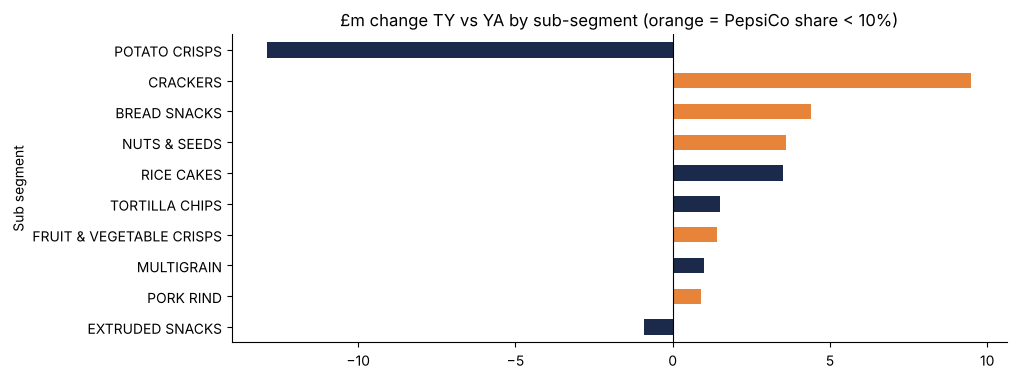

In [21]:
top = sg.reindex(sg['£m change'].abs().sort_values(ascending=False).index).head(10)
colors = [ORANGE if s < 10 else NAVY for s in top['PepsiCo share %']]
ax = top['£m change'][::-1].plot.barh(color=colors[::-1], title='£m change TY vs YA by sub-segment (orange = PepsiCo share < 10%)')
ax.axvline(0, color='black', lw=.8); plt.show()

**What we learn**
- Market is almost flat (+1.2%); **online grows +5.8% and delivers ~80% of the growth**.
- PepsiCo loses ~0.9 pts share in both channels.
- **Acadia** is the fastest-growing customer (+15.5%) but PepsiCo's share there is the lowest (~25%) and falling.
- Core Potato Crisps declines (-£12.9m); growth comes from Crackers, Bread Snacks, Nuts, Rice Cakes, F&V crisps – mostly where **PepsiCo has little or no share**.
→ *Hypotheses for analysis: (H1) PepsiCo is under-represented where growth is; (H2) online/Acadia is the place to fix it.*

## Step 8 – Channel mix: what over-trades online?
**Online Index** = share of online sales ÷ share of in-store sales × 100 (>100 = more important online).

In [22]:
def online_index(col):
    m = ty.pivot_table(index=col, columns='Channel', values='VALUE SALES', aggfunc='sum', fill_value=0)
    m = m / m.sum()
    m['Online index'] = m['Online'] / m['In-store'] * 100
    return m.sort_values('Online', ascending=False).round(3)
online_index('Sub pack format')

Channel,In-store,Online,Online index
Sub pack format,,,
SMALL MULTIPACK,0.28,0.40,143.97
SHARING,0.39,0.32,82.60
NUTS,0.10,0.08,84.11
MEDIUM MULTIPACK,0.05,0.08,153.97
LARGE MULTIPACK,0.03,0.07,228.25
STANDARDS,0.07,0.03,40.80
SALSA DIPS,0.01,0.01,64.13
GRABS,0.07,0.01,8.16


In [23]:
online_index('Sub segment').head(12)

Channel,In-store,Online,Online index
Sub segment,,,
POTATO CRISPS,0.40,0.36,88.22
EXTRUDED SNACKS,0.21,0.26,119.11
NUTS & SEEDS,0.09,0.08,84.26
CRACKERS,0.06,0.07,119.94
TORTILLA CHIPS,0.07,0.05,77.87
RICE CAKES,0.02,0.03,213.37
POPCORN (READY TO EAT),0.03,0.03,93.41
BREAD SNACKS,0.02,0.03,162.84
SNACK MIX,0.04,0.03,68.32


**What we learn**
- **Multipacks over-trade online** (index ~144–228); single packs (Grabs, Standards) barely sell online → online is the **big-basket, planned** channel.
- Better-for-you / adjacent sub-segments (Rice Cakes, Bread Snacks, F&V crisps) over-trade online.
→ *Hypothesis (H3): online is the AWOP lever – bigger packs and bundles.*

## Step 9 – Price per unit (excluding zero-sales rows)

In [24]:
p = ty[ty['UNIT SALES'] > 0].groupby(['Sub pack format', 'PepsiCo'])[['VALUE SALES', 'UNIT SALES']].sum()
ppu = (p['VALUE SALES'] / p['UNIT SALES']).unstack().rename(columns={False: 'Competitors £/unit', True: 'PepsiCo £/unit'})
ppu['PepsiCo price index'] = ppu['PepsiCo £/unit'] / ppu['Competitors £/unit'] * 100
ppu.round(2)

PepsiCo,Competitors £/unit,PepsiCo £/unit,PepsiCo price index
Sub pack format,,,
GRABS,0.92,0.86,93.92
LARGE MULTIPACK,3.92,4.28,109.29
MEDIUM MULTIPACK,2.69,3.05,113.42
NUTS,2.13,1.87,87.92
SALSA DIPS,1.42,2.07,145.50
SHARING,1.47,1.82,124.12
SMALL MULTIPACK,1.56,1.77,113.52
STANDARDS,1.23,0.87,70.94


**What we learn:** PepsiCo is priced **above competitors in Sharing** (~£1.82 vs ~£1.47 per unit) and multipacks. Possible reason for its weak sharing share → *test in analysis: is the sharing gap price or range?*

## Step 10 – PepsiCo portfolio: which brands grow or decline?

In [25]:
pb = d[d.PepsiCo].pivot_table(index='Brand Name', columns='Period', values='VALUE SALES', aggfunc='sum', fill_value=0) / 1e6
pb['growth %'] = (pb.TY / pb.YA - 1) * 100
pb.sort_values('TY', ascending=False).head(12).round(1)

Period,TY,YA,growth %
Brand Name,,,
CoastalVale,129.10,129.70,-0.50
AmberGrove,61.50,60.40,1.80
AlderVale,35.00,37.00,-5.50
AmberHearth,34.70,37.60,-7.60
RedRidge,25.60,26.10,-2.10
HighlandMeadow,20.00,21.50,-7.10
HighlandRidge,14.70,15.50,-5.00
WestGrove,14.40,17.20,-16.40
BlueMeadow,10.80,10.90,-0.40


**What we learn:** the flagship (CoastalVale) is flat and most big PepsiCo brands decline; small brands in nuts / multigrain / rice cakes grow fast from a low base.

## Step 11 – Shopper tabs
### 11a. Demographic Data – check totals, then compare mixes

In [26]:
print(dem.groupby(['Dimension', 'Channel'])['Shopper_count'].sum().unstack())   # check: same total per dimension?
mixd = dem.pivot_table(index=['Dimension', 'Category'], columns='Channel', values='Shopper_count', aggfunc='sum', fill_value=0)
mixd = mixd / mixd.groupby(level=0).transform('sum')
mixd['Online index'] = mixd['E-commerce'] / mixd['In-store'] * 100
mixd.round(2)

Channel     E-commerce  In-store
Dimension                       
Age               8000     12000
Life stage        8000     12000
Mission           8000     12000


Channel                        E-commerce  In-store  Online index
Dimension  Category                                              
Age        28–35                     0.09      0.08        112.50
           35–44                     0.23      0.18        127.78
           45–54                     0.27      0.22        122.73
           55–64                     0.20      0.22         90.91
           65+                       0.19      0.27         70.37
           <28                       0.02      0.03         66.67
Life stage Empty nesters             0.20      0.23         86.96
           Families with kids        0.52      0.41        126.83
           Pre-families              0.10      0.11         90.91
           Retired                   0.18      0.25         72.00
Mission    Main shop                 0.79      0.43        183.72
           Other missions            0.05      0.08         62.50
           Replenish                 0.16      0.37         43.24
           Top-up                    0.00      0.12          0.00

**What we learn:** each dimension totals 12,000 in-store and 8,000 e-commerce shoppers (sample). Online over-indexes on **families with kids (127)**, **ages 35–54** and the **main-shop mission (79% vs 43%)**; retired / 65+ under-index. E-commerce has no top-up mission.

### 11b. Basket_bands – each retailer has 1,000 baskets per channel group

[1000]


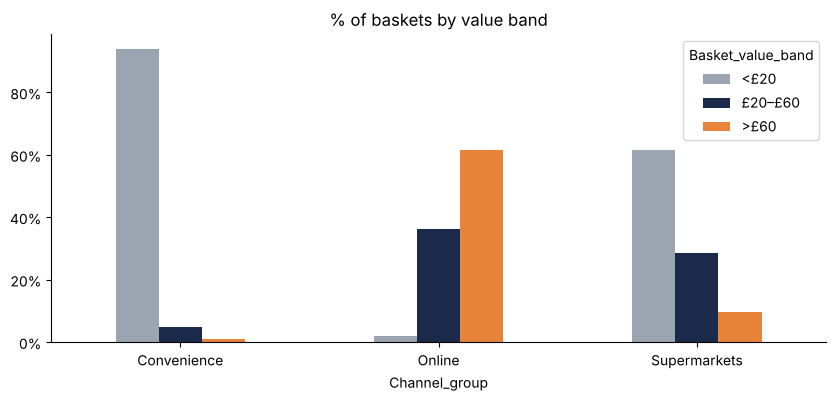

Basket_value_band,<£20,£20–£60,>£60
Channel_group,,,
Convenience,0.94,0.05,0.01
Online,0.02,0.36,0.62
Supermarkets,0.62,0.29,0.10


In [27]:
print(bb.groupby(['Channel_group', 'Retailer'])['Basket_count'].sum().unique())   # check: 1,000 per retailer per channel group
band = bb.pivot_table(index='Channel_group', columns='Basket_value_band', values='Basket_count', aggfunc='sum')[['<£20', '£20–£60', '>£60']]
band_pct = band.div(band.sum(axis=1), axis=0)
ax = band_pct.plot.bar(color=[GREY, NAVY, ORANGE], rot=0, title='% of baskets by value band')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}')); plt.show()
band_pct.round(2)

**What we learn:** convenience = small baskets (94% < £20); online = big baskets (62% > £60). Note: some retailers here (Escora Express, Co-op, Westridge) are **not in the sales data** – treat as a separate shopper sample.

### 11c. CSN_metrics – nuts & snacks in online vs offline baskets

In [28]:
c = csn.set_index('Channel')[['Total_baskets', 'Baskets_with_CSN', 'Total_CSN_spend_GBP']]
c['CSN basket penetration'] = c.Baskets_with_CSN / c.Total_baskets
c['£ per CSN basket'] = c.Total_CSN_spend_GBP / c.Baskets_with_CSN
c['CSN £ per basket (all)'] = c.Total_CSN_spend_GBP / c.Total_baskets
c.round(2)

,Total_baskets,Baskets_with_CSN,Total_CSN_spend_GBP,CSN basket penetration,£ per CSN basket,CSN £ per basket (all)
Channel,,,,,,
Online,5000,2450,10290,0.49,4.20,2.06
Offline,8000,1840,5152,0.23,2.80,0.64


**What we learn:** online baskets are **2.1x** more likely to contain CSN (49% vs 23%) and spend **1.5x** more when they do (£4.20 vs £2.80) – a proxy for higher penetration and AWOP online.

### 11d. Basket_Combination_Data – who buys what together

In [29]:
cbx = cb.dropna(subset=['Primary Brand']).copy()
sup_map = d.drop_duplicates('Brand Name').set_index('Brand Name')['SUPPLIER']
cbx['Primary supplier'] = cbx['Primary Brand'].map(sup_map).fillna('(category)')
cbx['Cross supplier'] = cbx['Cross Brand Buying'].map(sup_map).fillna('(category)')
cbx[['Primary Brand', 'Primary supplier', 'Cross Brand Buying', 'Cross supplier', 'Percent_Buyers_Also_Bought']]

,Primary Brand,Primary supplier,Cross Brand Buying,Cross supplier,Percent_Buyers_Also_Bought
0,All Nuts,(category),PC Sharing,(category),80.00
1,All Nuts,(category),SMPC,(category),78.00
2,All Nuts,(category),Extruded Sharing,(category),57.00
3,WestGrove,PepsiCo,AlderVale,PepsiCo,51.00
4,AlderVale,PepsiCo,AmberGrove,PepsiCo,40.00
5,CopperTrail,PepsiCo,SunnyCrown,Valley Trail Foods,54.00
6,AmberHearth,PepsiCo,AmberGrove,PepsiCo,55.00


**What we learn:** 80% of nuts buyers also buy potato-crisp sharing packs; most brand pairs are **PepsiCo + PepsiCo** (portfolio bundles); CopperTrail buyers also buy a competitor's popcorn. Limitation: one-directional and no base rate → no affinity index.

## Step 12 – EDA summary

### Data decisions (put these on the Assumptions slide)
| # | Decision | Why |
|---|---|---|
| 1 | Compare 2025 wk1–47 (TY) vs 2024 wk1–47 (YA) | 2025 ends wk47; wks 48–52 are the Christmas peak |
| 2 | Online = E-COMMERCE + PURE PLAY; In-store = LARGE + SMALL; drop UNALLOCATED | No channel column; UNALLOCATED ≈ £5.5k (negligible) |
| 3 | Analyse at Sub segment level | Segment mixes product type with 'Private label' |
| 4 | Keep duplicates & missing-value rows | Negligible £ impact; fields not needed |
| 5 | Exclude zero-sales rows from price calculations | 17% of rows are zero and would bias averages |
| 6 | Treat brand as Brand + Supplier | Sanitised brand names reused across suppliers |
| 7 | Value share/growth as penetration proxy | No buyer counts in sales data |

### Key observations
1. Flat market (+1.2%); online +5.8% = ~80% of growth; PepsiCo −0.9 pts share.
2. Growth is in sub-segments where PepsiCo is weak/absent; PepsiCo's core is declining.
3. Sharing is the biggest pack and PepsiCo's weakest (and PepsiCo is priced higher there).
4. Online = big, planned, family baskets; multipacks and better-for-you over-trade online.
5. Acadia: fastest growth, lowest PepsiCo share.
6. Nuts buyers also buy crisps; PepsiCo brands are bought together.

### Hypotheses to test in the analysis
- **H1:** PepsiCo's biggest gap is pack/sub-segment specific (e.g. Potato Crisps × Sharing) → *whitespace grid*
- **H2:** PepsiCo is weaker online than in-store in specific cells → *online vs in-store gap*
- **H3:** Online is the AWOP lever (multipacks, bundles) → *basket + CSN + online index*
- **H4:** Acadia's gap is partly range (fixable) and partly mix (shoppers buy adjacencies) → *Acadia vs other online*